In [7]:
from pathlib import Path
import zipfile, tarfile

ROOT = Path.cwd()
work_dir = ROOT / 'spam_project'
work_dir.mkdir(parents=True, exist_ok=True)
zip_files = [Path('lingspam.zip'), Path('spamassassin.zip')]
test_archive_path = Path('test_task_emails.tar.xz')
for archive in [*zip_files, test_archive_path]:
    if not archive.is_file():
        raise FileNotFoundError(f'Нет файла: {archive.resolve()}')
for archive in zip_files:
    if not zipfile.is_zipfile(archive):
        raise ValueError(f'{archive.name} повреждён или загружен не полностью. Перезагрузите оригинал.')
    target = work_dir / archive.stem
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        bad = z.testzip()
        if bad:
            raise ValueError(f'{archive.name}: повреждён файл {bad}')
        z.extractall(target)
    print(f'{archive.name} → {target}')
if not tarfile.is_tarfile(test_archive_path):
    raise ValueError('Повреждён test_task_emails.tar.xz')
print('Внешний тест:', test_archive_path)

lingspam.zip → /content/spam_project/lingspam
spamassassin.zip → /content/spam_project/spamassassin
Внешний тест: test_task_emails.tar.xz


In [8]:

import io, re, html, email
import pandas as pd
from email import policy
from email.parser import BytesParser
from IPython.display import display


## Очистка LingSpam

В CSV объединяются поля `subject` и `message`. Метка `0` означает обычное письмо, `1` — спам.

In [9]:
# Источники LingSpam: CSV либо отдельные письма msg*/spmsg*
ling_dir = work_dir / 'lingspam'
csv_files = sorted(ling_dir.rglob('messages.csv'))
if not csv_files:
    csv_files = sorted(ling_dir.rglob('*.csv'))
ling = None
if csv_files:
    for candidate in csv_files:
        try:
            frame = pd.read_csv(candidate)
            if {'subject', 'message', 'label'}.issubset(frame.columns):
                ling = frame
                print('LingSpam CSV:', candidate)
                break
        except (UnicodeError, pd.errors.ParserError):
            continue
if ling is None:
    print('CSV с subject/message/label нет — будут прочитаны отдельные письма.')

LingSpam CSV: /content/spam_project/lingspam/messages.csv


## Очистка SpamAssassin

Из писем извлекаются тема и текстовые MIME-части.

In [10]:
# 5. Универсальная очистка текста

def clean_text(x):
    x = html.unescape('' if x is None else str(x))
    x = re.sub(r'<style.*?</style>|<script.*?</script>', ' ', x, flags=re.I|re.S)
    x = re.sub(r'<[^>]+>', ' ', x)
    x = re.sub(r'https?://\S+|www\.\S+', ' URL ', x, flags=re.I)
    x = re.sub(r'\S+@\S+', ' EMAIL ', x)
    x = re.sub(r'[^\w\s!?$%+\-]', ' ', x, flags=re.UNICODE)
    return re.sub(r'\s+', ' ', x).strip().lower()

def decode_part(part):
    try:
        data = part.get_payload(decode=True)
        if data is None: return str(part.get_payload())
        return data.decode(part.get_content_charset() or 'utf-8', errors='replace')
    except Exception:
        return ''

def email_to_text(raw):
    msg = BytesParser(policy=policy.default).parsebytes(raw)
    parts = msg.walk() if msg.is_multipart() else [msg]
    body = [decode_part(p) for p in parts
            if p.get_content_maintype() == 'text' and p.get_content_disposition() != 'attachment']
    return str(msg.get('subject', '')) + ' ' + ' '.join(body)


In [11]:
# 6. Подготовка LingSpam (работает и без переменной ling)
ling_rows = []
if ling is not None:
    for _, row in ling.iterrows():
        value = str(row['label']).strip().lower()
        if value in {'1', '1.0', 'spam'}:
            label = 1
        elif value in {'0', '0.0', 'ham', 'normal', 'nonspam', 'non-spam'}:
            label = 0
        else:
            continue
        text = clean_text(f"{row.get('subject', '')} {row.get('message', '')}")
        if text:
            ling_rows.append({'text': text, 'label': label, 'source': 'LingSpam'})
else:
    for path in ling_dir.rglob('*'):
        if not path.is_file() or path.suffix.lower() not in {'', '.txt'}:
            continue
        name = path.name.lower()
        if name.startswith('spmsg'):
            label = 1
        elif name.startswith('msg'):
            label = 0
        else:
            continue
        text = clean_text(path.read_text(encoding='latin-1', errors='replace'))
        if text:
            ling_rows.append({'text': text, 'label': label, 'source': 'LingSpam'})
ling_clean = pd.DataFrame(ling_rows, columns=['text', 'label', 'source'])
print('LingSpam после очистки:', ling_clean.shape)
if ling_clean.empty:
    print('Примеры файлов:', [str(p.relative_to(ling_dir)) for p in list(ling_dir.rglob('*'))[:15]])
    raise ValueError('LingSpam: не удалось прочитать письма. Проверьте структуру архива.')
print(ling_clean['label'].value_counts())

LingSpam после очистки: (2893, 3)
label
0    2412
1     481
Name: count, dtype: int64


In [12]:
# Подготовка SpamAssassin
folders = {'easy_ham': 0, 'hard_ham': 0, 'easy_ham_2': 0, 'spam': 1, 'spam_2': 1}
spam_rows = []
for path in (work_dir / 'spamassassin').rglob('*'):
    if not path.is_file() or '__MACOSX' in str(path) or path.name == 'cmds':
        continue
    folder = next((part for part in path.parts if part.lower() in folders), None)
    if folder is None:
        continue
    try:
        text = clean_text(email_to_text(path.read_bytes()))
        if text:
            spam_rows.append({'text': text, 'label': folders[folder.lower()], 'source': 'SpamAssassin'})
    except Exception:
        continue
spam_clean = pd.DataFrame(spam_rows, columns=['text', 'label', 'source'])
print('SpamAssassin после очистки:', spam_clean.shape)


SpamAssassin после очистки: (4197, 3)


In [13]:
# 8. Объединение, удаление дублей и коротких записей
clean_df = pd.concat([ling_clean, spam_clean], ignore_index=True)
clean_df = clean_df.drop_duplicates(subset='text')
clean_df = clean_df[clean_df['text'].str.len() >= 20].reset_index(drop=True)
clean_df['label_name'] = clean_df['label'].map({0: 'ham', 1: 'spam'})
print('Итоговый размер:', clean_df.shape)
display(clean_df.groupby(['source','label_name']).size().unstack(fill_value=0))
display(clean_df.head())


Итоговый размер: (6818, 4)


label_name,ham,spam
source,,
LingSpam,2405,468
SpamAssassin,2638,1307


In [14]:
# Первичные таблицы
clean_df.to_csv(ROOT / 'spam_combined_clean.csv', index=False)
clean_df.groupby(['source', 'label_name']).size().unstack(fill_value=0).to_csv(ROOT / 'dataset_summary.csv')


In [15]:
print("Размер датасета:", clean_df.shape)

print("\nПропуски:")
print(clean_df.isna().sum())

print("\nДубликаты текстов:", clean_df['text'].duplicated().sum())

print("\nРаспределение классов:")
print(clean_df['label_name'].value_counts())

print("\nДлина текстов:")
print(clean_df['text'].str.len().describe())


Размер датасета: (6818, 4)

Пропуски:
text          0
label         0
source        0
label_name    0
dtype: int64

Дубликаты текстов: 0

Распределение классов:
label_name
ham     5043
spam    1775
Name: count, dtype: int64

Длина текстов:
count     6818.000000
mean      2254.162218
std       3652.213161
min         21.000000
25%        580.250000
50%       1138.500000
75%       2482.250000
max      83008.000000
Name: text, dtype: float64


In [16]:
# Финальная проверка данных
clean_df = clean_df.dropna(subset=['text', 'label']).copy()
clean_df['text'] = clean_df['text'].astype(str).str.strip().str.slice(0, 30000)
clean_df = clean_df[clean_df['text'].str.len() >= 20]
clean_df = clean_df.drop_duplicates(subset=['text']).reset_index(drop=True)
clean_df['label'] = clean_df['label'].astype(int)
clean_df['label_name'] = clean_df['label'].map({0: 'ham', 1: 'spam'})
if clean_df['label'].nunique() < 2:
    raise ValueError('В обучающих данных должны присутствовать оба класса.')
clean_df.to_csv(ROOT / 'spam_combined_clean.csv', index=False)
clean_df.groupby(['source','label_name']).size().unstack(fill_value=0).to_csv(ROOT / 'dataset_summary.csv')
print('После проверки:', clean_df.shape)


После проверки: (6818, 4)


In [17]:
print(clean_df.groupby(["source", "label_name"]).size().unstack(fill_value=0))

print("\nДоля классов:")
print(clean_df["label_name"].value_counts(normalize=True).mul(100).round(2))

label_name     ham  spam
source                  
LingSpam      2405   468
SpamAssassin  2638  1307

Доля классов:
label_name
ham     73.97
spam    26.03
Name: proportion, dtype: float64


In [18]:
# 14. Разделение на обучающую и тестовую выборки

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    clean_df["text"],
    clean_df["label"],
    test_size=0.20,
    random_state=42,
    stratify=clean_df["label"]
)

print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))

Обучающая выборка: 5454
Тестовая выборка: 1364


In [19]:
# 15. Проверка баланса после разделения

print("Train:")
print(y_train.value_counts())

print("\nTest:")
print(y_test.value_counts())

Train:
label
0    4034
1    1420
Name: count, dtype: int64

Test:
label
0    1009
1     355
Name: count, dtype: int64


In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [21]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        max_features=150000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="liblinear",
        random_state=42
    ))
])

print(model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.98, max_features=150000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42, solver='liblinear'))])


In [22]:
# 18. Кросс-валидация

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

for metric in scoring:
    values = cv_results["test_" + metric]
    print(
        f"{metric}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )

precision: 0.9707 ± 0.0092
recall: 0.9556 ± 0.0065
f1: 0.9631 ± 0.0064


              precision    recall  f1-score   support

         ham       0.98      0.99      0.98      1009
        spam       0.98      0.93      0.96       355

    accuracy                           0.98      1364
   macro avg       0.98      0.96      0.97      1364
weighted avg       0.98      0.98      0.98      1364

Матрица ошибок:
[[1003    6]
 [  25  330]]


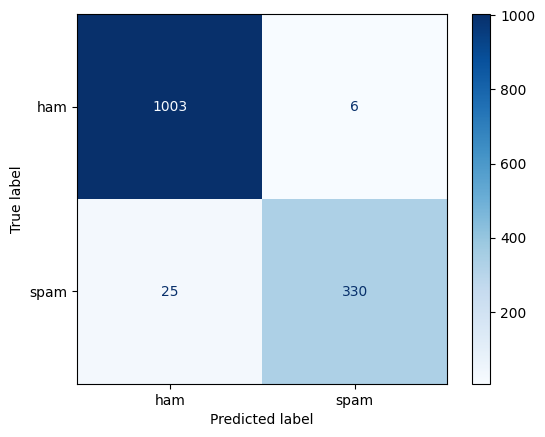

In [23]:
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print(classification_report(
    y_test,
    predictions,
    target_names=["ham", "spam"]
))

matrix = confusion_matrix(y_test, predictions)
print("Матрица ошибок:")
print(matrix)

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["ham", "spam"]
).plot(cmap="Blues")

plt.show()

In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score

probabilities = model.predict_proba(X_test)[:, 1]
for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    print(f'Порог {threshold:.2f} | Precision {precision_score(y_test,pred,zero_division=0):.4f} | '
          f'Recall {recall_score(y_test,pred,zero_division=0):.4f} | '
          f'F1 {f1_score(y_test,pred,zero_division=0):.4f} | FP {fp}')


Порог 0.50 | Precision 0.9821 | Recall 0.9296 | F1 0.9551 | FP 6
Порог 0.60 | Precision 0.9844 | Recall 0.8901 | F1 0.9349 | FP 5
Порог 0.70 | Precision 0.9868 | Recall 0.8451 | F1 0.9105 | FP 4
Порог 0.80 | Precision 0.9925 | Recall 0.7465 | F1 0.8521 | FP 2
Порог 0.90 | Precision 1.0000 | Recall 0.4507 | F1 0.6214 | FP 0


In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            max_features=150000
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="liblinear",
            random_state=42
        ))
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            max_features=150000
        )),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
            max_features=150000
        )),
        ("classifier", MultinomialNB())
    ])
}

for name, current_model in models.items():
    results = cross_validate(
        current_model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=-1
    )

    print(f"\n{name}")
    print("Precision:", round(results["test_precision"].mean(), 4))
    print("Recall:", round(results["test_recall"].mean(), 4))
    print("F1:", round(results["test_f1"].mean(), 4))


Logistic Regression
Precision: 0.9707
Recall: 0.9556
F1: 0.9631

Linear SVM
Precision: 0.9828
Recall: 0.9648
F1: 0.9737

Naive Bayes
Precision: 0.999
Recall: 0.6915
F1: 0.8172


In [26]:
import tarfile

with tarfile.open(test_archive_path, "r:xz") as archive:
    test_names = archive.getnames()

print("Количество файлов в архиве:", len(test_names))

for name in test_names[:30]:
    print(name)

Количество файлов в архиве: 1602
ham
ham/000.eml
ham/001.eml
ham/002.eml
ham/003.eml
ham/004.eml
ham/005.eml
ham/006.eml
ham/007.eml
ham/008.eml
ham/009.eml
ham/010.eml
ham/011.eml
ham/012.eml
ham/013.eml
ham/014.eml
ham/015.eml
ham/016.eml
ham/017.eml
ham/018.eml
ham/019.eml
ham/020.eml
ham/021.eml
ham/022.eml
ham/023.eml
ham/024.eml
ham/025.eml
ham/026.eml
ham/027.eml
ham/028.eml


In [27]:
# Распаковка внешнего теста
from pathlib import Path
import tarfile

test_spam_dir = ROOT / 'test_spam'
test_spam_dir.mkdir(exist_ok=True)
with tarfile.open(test_archive_path, 'r:xz') as archive:
    root = test_spam_dir.resolve()
    members = archive.getmembers()
    for member in members:
        target = (root / member.name).resolve()
        if not target.is_relative_to(root) or member.issym() or member.islnk() or member.isdev():
            raise ValueError(f'Небезопасный путь в архиве: {member.name}')
    for member in members:
        if member.isfile():
            dest = root / member.name
            dest.parent.mkdir(parents=True, exist_ok=True)
            with archive.extractfile(member) as source, open(dest, 'wb') as output:
                import shutil
                shutil.copyfileobj(source, output)
print('Архив распакован в:', test_spam_dir)


Архив распакован в: /content/test_spam


In [28]:
test_files = [
    path for path in test_spam_dir.rglob("*")
    if path.is_file()
]

print("Всего файлов:", len(test_files))

for path in test_files[:30]:
    print(path)

Всего файлов: 1600
/content/test_spam/spam/723.eml
/content/test_spam/spam/940.eml
/content/test_spam/spam/629.eml
/content/test_spam/spam/114.eml
/content/test_spam/spam/185.eml
/content/test_spam/spam/068.eml
/content/test_spam/spam/656.eml
/content/test_spam/spam/748.eml
/content/test_spam/spam/932.eml
/content/test_spam/spam/014.eml
/content/test_spam/spam/651.eml
/content/test_spam/spam/809.eml
/content/test_spam/spam/213.eml
/content/test_spam/spam/560.eml
/content/test_spam/spam/237.eml
/content/test_spam/spam/546.eml
/content/test_spam/spam/572.eml
/content/test_spam/spam/534.eml
/content/test_spam/spam/291.eml
/content/test_spam/spam/453.eml
/content/test_spam/spam/635.eml
/content/test_spam/spam/162.eml
/content/test_spam/spam/523.eml
/content/test_spam/spam/022.eml
/content/test_spam/spam/779.eml
/content/test_spam/spam/084.eml
/content/test_spam/spam/153.eml
/content/test_spam/spam/329.eml
/content/test_spam/spam/837.eml
/content/test_spam/spam/766.eml


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        sublinear_tf=True,
        max_features=150000
    )),
    ("classifier", CalibratedClassifierCV(
        estimator=LinearSVC(
            class_weight="balanced",
            random_state=42
        ),
        method="sigmoid",
        cv=5
    ))
])

print("TF-IDF + Linear SVM")

TF-IDF + Linear SVM


In [31]:
final_model.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.98, max_features=150000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 CalibratedClassifierCV(cv=5,
                                        estimator=LinearSVC(class_weight='balanced',
                                                            random_state=42)))])

              precision    recall  f1-score   support

         ham       0.98      0.99      0.99      1009
        spam       0.98      0.94      0.96       355

    accuracy                           0.98      1364
   macro avg       0.98      0.97      0.97      1364
weighted avg       0.98      0.98      0.98      1364

Матрица ошибок:
 [[1003    6]
 [  20  335]]


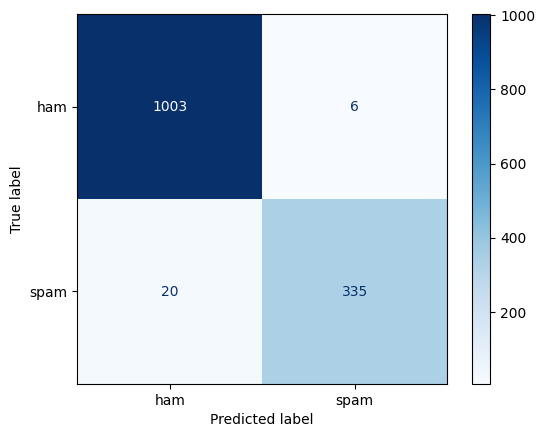

In [32]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred_final_holdout = final_model.predict(X_test)
print(classification_report(y_test, pred_final_holdout, labels=[0,1],
                            target_names=['ham','spam'], zero_division=0))
matrix = confusion_matrix(y_test, pred_final_holdout, labels=[0,1])
print('Матрица ошибок:\n', matrix)
ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=['ham','spam']).plot(cmap='Blues')
plt.show()


In [33]:

def get_label_from_path(path):
    parent_name = Path(path).parent.name.lower()
    if parent_name == 'spam':
        return 1
    if parent_name in {'ham', 'normal', 'nonspam', 'non-spam'}:
        return 0
    return None


In [34]:

rows = []
for path in test_spam_dir.rglob('*'):
    if not path.is_file():
        continue
    try:
        text = clean_text(email_to_text(path.read_bytes()))
        if len(text) >= 20:
            rows.append({'file': str(path), 'text': text, 'label': get_label_from_path(path)})
    except Exception as exc:
        print('Ошибка чтения:', path.name, exc)
test_spam_df = pd.DataFrame(rows, columns=['file','text','label'])
print('Количество писем:', len(test_spam_df))
display(test_spam_df.head())


Количество писем: 1596


In [ ]:
print(
    test_spam_df["label"].value_counts(dropna=False)
)

if test_spam_df["label"].isna().all():
    print("В архиве нет правильных меток ham/spam.")
else:
    print("Метки найдены, можно рассчитать метрики.")

In [35]:

THRESHOLD = 0.60  # более строгий порог: снижает FP, но может снизить Recall
if not test_spam_df.empty:
    test_spam_df['spam_probability'] = final_model.predict_proba(test_spam_df['text'])[:, 1]
    test_spam_df['prediction'] = (test_spam_df['spam_probability'] >= THRESHOLD).astype(int)
    test_spam_df['prediction_name'] = test_spam_df['prediction'].map({0:'ham',1:'spam'})
else:
    test_spam_df['spam_probability'] = pd.Series(dtype=float)
    test_spam_df['prediction'] = pd.Series(dtype=int)
    test_spam_df['prediction_name'] = pd.Series(dtype=str)
display(test_spam_df[['file','spam_probability','prediction_name']].head(20))


In [36]:

labeled_test_spam = test_spam_df.dropna(subset=['label']).copy()
if not labeled_test_spam.empty:
    print(classification_report(labeled_test_spam['label'].astype(int),
                                labeled_test_spam['prediction'].astype(int),
                                labels=[0,1], target_names=['ham','spam'], zero_division=0))
    test_spam_matrix = confusion_matrix(labeled_test_spam['label'].astype(int),
                                        labeled_test_spam['prediction'].astype(int), labels=[0,1])
    print('Матрица ошибок:\n', test_spam_matrix)
else:
    print('Метки не найдены: доступны только прогнозы.')


              precision    recall  f1-score   support

         ham       0.86      0.99      0.92       600
        spam       0.99      0.90      0.95       996

    accuracy                           0.94      1596
   macro avg       0.93      0.95      0.93      1596
weighted avg       0.94      0.94      0.94      1596

Матрица ошибок:
 [[593   7]
 [ 96 900]]


In [37]:
test_spam_df.to_csv(ROOT / 'test_spam_predictions.csv', index=False)
print('Сохранено:', ROOT / 'test_spam_predictions.csv')


Сохранено: /content/test_spam_predictions.csv


## Упаковка модели и сервиса


In [41]:
import json, joblib, shutil

bundle_dir = ROOT / 'spam_delivery'
bundle_dir.mkdir(exist_ok=True)
joblib.dump({'pipeline': final_model, 'threshold': THRESHOLD}, bundle_dir / 'spam_model.joblib')

metrics = {
    'threshold': THRESHOLD,
    'cv_logreg': {k: float(cv_results['test_'+k].mean()) for k in ('precision','recall','f1')},
    'holdout_final': classification_report(y_test, pred_final_holdout, labels=[0,1],
                 target_names=['ham','spam'], output_dict=True, zero_division=0),
    'holdout_confusion_matrix': matrix.tolist(),
    'external_test_count': int(len(test_spam_df)),
    'external_labeled_count': int(len(labeled_test_spam))
}
if not labeled_test_spam.empty:
    metrics['external_test'] = classification_report(
        labeled_test_spam['label'].astype(int), labeled_test_spam['prediction'].astype(int),
        labels=[0,1], target_names=['ham','spam'], output_dict=True, zero_division=0)
    metrics['external_confusion_matrix'] = test_spam_matrix.tolist()
(bundle_dir / 'metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
for file_name in ('spam_combined_clean.csv','dataset_summary.csv','test_spam_predictions.csv'):
    shutil.copy2(ROOT / file_name, bundle_dir / file_name)

app_code = r'''from pathlib import Path
import re, html
import joblib
from fastapi import FastAPI
from pydantic import BaseModel

bundle = joblib.load(Path(__file__).with_name('spam_model.joblib'))
app = FastAPI(title='Spam classifier')

def clean_text(x):
    x = html.unescape('' if x is None else str(x))
    x = re.sub(r'<style.*?</style>|<script.*?</script>', ' ', x, flags=re.I|re.S)
    x = re.sub(r'<[^>]+>', ' ', x)
    x = re.sub(r'https?://\S+|www\.\S+', ' URL ', x, flags=re.I)
    x = re.sub(r'\S+@\S+', ' EMAIL ', x)
    x = re.sub(r'[^\w\s!?$%+\-]', ' ', x, flags=re.UNICODE)
    return re.sub(r'\s+', ' ', x).strip().lower()

class EmailInput(BaseModel):
    text: str

@app.get('/health')
def health():
    return {'status': 'ok'}

@app.post('/predict')
def predict(item: EmailInput):
    score = float(bundle['pipeline'].predict_proba([clean_text(item.text)])[0, 1])
    return {'label': 'spam' if score >= bundle['threshold'] else 'ham',
            'spam_probability': score, 'threshold': bundle['threshold']}
'''
(bundle_dir / 'app.py').write_text(app_code, encoding='utf-8')
(bundle_dir / 'requirements.txt').write_text(
    'fastapi>=0.110,<1\nuvicorn>=0.29,<1\nscikit-learn>=1.4,<2\njoblib>=1.3,<2\npydantic>=2,<3\n', encoding='utf-8')
(bundle_dir / 'Dockerfile').write_text(
    'FROM python:3.11-slim\nWORKDIR /app\nCOPY requirements.txt .\nRUN pip install --no-cache-dir -r requirements.txt\nCOPY app.py spam_model.joblib ./\nEXPOSE 8000\nCMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]\n', encoding='utf-8')
(bundle_dir / '.dockerignore').write_text('*.csv\n*.json\n*.zip\n__pycache__/\n', encoding='utf-8')
(bundle_dir / 'README.md').write_text(
    '# Spam classifier\n\nTF-IDF + калиброванный LinearSVC. Порог: 0.60.\n\n'
    '```bash\ndocker build -t spam-project .\ndocker run -p 8000:8000 spam-project\n```\n\n'
    'GET /health; POST /predict с JSON `{"text":"Example email"}`.\n', encoding='utf-8')

with zipfile.ZipFile(ROOT / 'Results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for path in bundle_dir.rglob('*'):
        if path.is_file():
            z.write(path, arcname=path.relative_to(bundle_dir))
print('Готово:', ROOT / 'Results.zip')


Готово: /content/Results.zip


In [44]:
# Скачивание ZIP
try:
    from google.colab import files
    files.download(str(ROOT / 'Results.zip'))
except ImportError:
    print('ZIP сохранён:', ROOT / 'Results.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>